# Sensormodell V1 — Optischer Durchflusssensor

Modellierung des Sensorsignals aus bekannter SPION-Konzentration im Kanal.  
Grundlage: Beer-Lambert'sches Gesetz, Basismodell (einzelner Strahl).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

## 1. Geometrie und Parameter

Koordinatensystem: y-Achse entlang Lichtweg (Lichtquelle → Sensor), z-Achse entlang Kanalachse.

- Schlauch: Innenradius $r_i$, Außenradius $r_a$
- $\alpha_S$: Absorptionskoeffizient Silikon [1/mm]
- $\beta$: Proportionalitätsfaktor SPION-Absorption [mL/(mg·mm)]

In [2]:
# Geometrie
r_i   = 3.17 / 2   # mm — Innenradius Schlauch
r_a   = r_i + 0.85  # mm — Außenradius Schlauch

# Optische Parameter
alpha_S = 2.0       # 1/mm — Absorptionskoeffizient Silikon
I_0     = 1.0       # W/m² — Eingangsintensität (normiert)

## 2. Kalibrierung — Bestimmung von β

**Modell (Basismodell, einzelner Strahl):**
$$I_\text{Sensor} = I_0 \cdot e^{-2\alpha_S(r_a - r_i)} \cdot e^{-\beta C}$$

Normierung auf Baseline ($c=0$, H₂O):
$$\frac{I_\text{Sensor}}{I_0} = e^{-\beta \cdot 2r_i \cdot c} \quad \Rightarrow \quad \ln\!\left(\frac{I_\text{Sensor}}{I_0}\right) = -\beta \cdot 2r_i \cdot c$$

**Vorgehen:** Logarithmieren → linearer Fit → Steigung ergibt $\beta$.

Sensor 0: beta = 0.2783 mL/(mg·mm),  R² = 0.9746
Sensor 1: beta = 0.2692 mL/(mg·mm),  R² = 0.9734
Sensor 2: beta = 0.2656 mL/(mg·mm),  R² = 0.9742


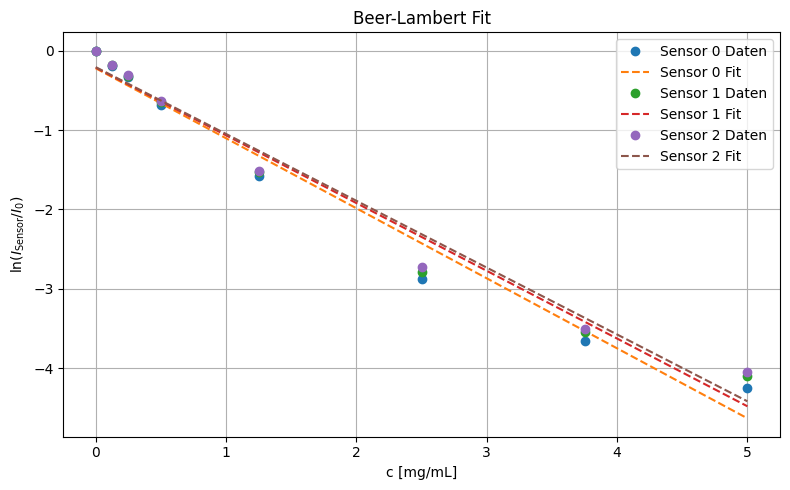


beta (Mittel alle Sensoren): 0.2710 mL/(mg·mm)


In [3]:
# Kalibrierkonzentrationen
c_pct  = np.array([0, 2.5, 5, 10, 25, 50, 75, 100])  # % von 5 mg/mL
c      = c_pct / 100 * 5.0                             # mg/mL

# Messwerte (Mittel aus 3 Replikaten) [ADC-Counts]
s0 = np.array([6175.75, 5095.25, 4450.42, 3109.02, 1277.47, 349.67, 158.51,  87.77])
s1 = np.array([6807.27, 5678.24, 4970.30, 3550.68, 1467.78, 419.97, 195.67, 112.47])
s2 = np.array([5772.13, 4826.33, 4245.17, 3053.35, 1272.14, 376.43, 173.69, 100.66])

betas = {}
plt.figure(figsize=(8, 5))

for name, s in [("Sensor 0", s0), ("Sensor 1", s1), ("Sensor 2", s2)]:
    I_0_cal      = s[0]                        # Baseline bei c=0 (H₂O)
    I_norm       = s / I_0_cal                 # I_Sensor / I_0
    log_I_norm   = np.log(I_norm)              # ln(I_Sensor/I_0)

    slope, intercept, r_corr, _, _ = linregress(c, log_I_norm)
    beta = -slope / (2 * r_i)                  # mL/(mg·mm)
    betas[name] = beta

    print(f"{name}: beta = {beta:.4f} mL/(mg·mm),  R² = {r_corr**2:.4f}")
    plt.plot(c, log_I_norm, 'o', label=f"{name} Daten")
    plt.plot(c, slope*c + intercept, '--', label=f"{name} Fit")

plt.xlabel("c [mg/mL]")
plt.ylabel(r"$\ln(I_\mathrm{Sensor}/I_0)$")
plt.title("Beer-Lambert Fit")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

beta = np.mean(list(betas.values()))
print(f"\nbeta (Mittel alle Sensoren): {beta:.4f} mL/(mg·mm)")

## 3. Rekalibrierung

Bei Sensor-Drift: Baseline $I_0$ vor jeder Messung mit H₂O neu bestimmen.  
$\beta$ bleibt konstant (aus Vollkalibrierung oben).

**Fehler 2-Punkt vs. Vollkalibrierung:** <6% — akzeptabel für Erstmodell.

In [4]:
def recalibrate_beta(I_0_new, I_100_new, c_100=5.0):
    """2-Punkt Rekalibrierung: beta aus 0% und 100%-Messung."""
    return -np.log(I_100_new / I_0_new) / (2 * r_i * c_100)

# Rekalibrierungsfehler vs. Vollkalibrierung
pairs = [(s0[0], s0[-1]), (s1[0], s1[-1]), (s2[0], s2[-1])]
for i, (I_0_new, I_100_new) in enumerate(pairs):
    b2 = recalibrate_beta(I_0_new, I_100_new)
    print(f"Sensor {i}: beta_2pt = {b2:.4f},  Abweichung = {abs(b2-beta)/beta*100:.1f}%")

Sensor 0: beta_2pt = 0.2684,  Abweichung = 1.0%
Sensor 1: beta_2pt = 0.2589,  Abweichung = 4.5%
Sensor 2: beta_2pt = 0.2555,  Abweichung = 5.8%


## 4. Sensormodell — Forward Model

**Basismodell (einzelner Strahl, x=0):**
$$I_\text{Sensor}(t) = I_0 \cdot e^{-\beta C(t)}$$

mit kumulativer Konzentration entlang des Lichtstrahls:
$$C(t) = 2\int_0^{r_i} c(r,\, t)\, dr$$

**Input:** $c(r, t)$ — radiales Konzentrationsprofil als 2D-Array `[Nr, Nt]`  
**Output:** $I_\text{Sensor}(t)$ — Sensorsignal als Zeitvektor

In [5]:
def sensor_signal(c_rt, r, beta, I_0_cal):
    """
    Berechnet I_Sensor(t) aus Konzentrationsprofil c(r, t).

    Parameter:
        c_rt    : 2D-Array [Nr, Nt] — Konzentration c(r,t) in mg/mL
        r       : r-Vektor [mm], von 0 bis r_i
        beta    : Absorptionskoeffizient [mL/(mg·mm)]
        I_0_cal : Baseline bei c=0 [ADC-Counts]

    Returns:
        I_sensor : Zeitvektor [ADC-Counts]
    """
    C_t = 2 * np.trapezoid(c_rt, r, axis=0)   # kumul. Konzentration (Nt,)
    return I_0_cal * np.exp(-beta * C_t)

## 5. Beispielanwendung — Synthetischer Bolus

Test des Modells mit synthetischem Bolus:  
- Gaußförmig in $t$, uniform in $r$  
- Ersatz für $c(r,t)$ vom Strömungsmodell

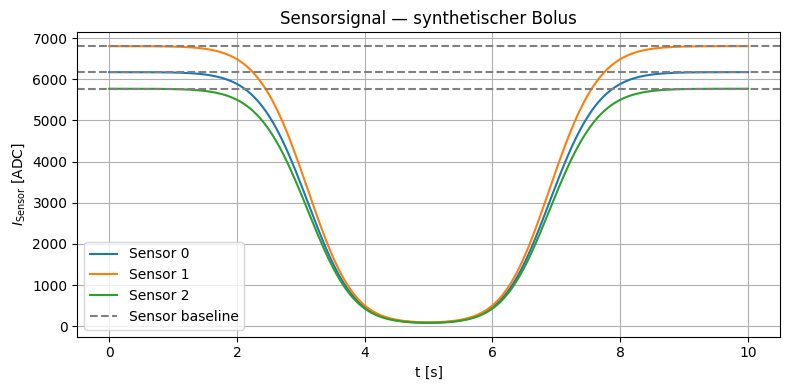

In [12]:
# Gitter
Nt, Nr    = 200, 50
t_max    = 10.0   # s
t         = np.linspace(0, t_max, Nt)    # s
r         = np.linspace(0, r_i, Nr)   # mm

# Synthetischer Bolus: Gauß in t, uniform in r
t_center  = t_max/2 # s — Bolus-Zentrum
sigma_t   = 1.0     # s — Bolus-Breite
c_peak    = 5     # mg/mL

c_rt = c_peak * np.exp(-(t[None,:] - t_center)**2 / (2*sigma_t**2)) \
       * np.ones((Nr, 1))   # [Nr, Nt]

I_0_s0   = s0[0]   # Baseline Sensor 0
I_0_s1   = s1[0]   # Baseline Sensor 1
I_0_s2   = s2[0]   # Baseline Sensor 2
I_s0  = sensor_signal(c_rt, r, beta, I_0_s0)
I_s1  = sensor_signal(c_rt, r, beta, I_0_s1)
I_s2  = sensor_signal(c_rt, r, beta, I_0_s2)

plt.figure(figsize=(8, 4))
plt.plot(t, I_s0, label='Sensor 0')
plt.plot(t, I_s1, label='Sensor 1')
plt.plot(t, I_s2, label='Sensor 2')
plt.axhline(I_0_s0, color='gray', linestyle='--', label='Sensor baseline')
plt.axhline(I_0_s1, color='gray', linestyle='--', )
plt.axhline(I_0_s2, color='gray', linestyle='--', )
plt.xlabel("t [s]")
plt.ylabel("$I_\\mathrm{Sensor}$ [ADC]")
plt.title("Sensorsignal — synthetischer Bolus")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 5b Anwendung auf Simulationsdaten

### Baseline und 100% Referenz für E02_20x15

| Sample | $I_{\mathrm{Baseline},A}$ / ADC | $I_{\mathrm{Baseline},B}$ / ADC | $I_{\mathrm{Baseline},\mathrm{Ref}}$ / ADC |
|---|---:|---:|---:|
| `E02_50R_AB_1` | 7616 | 5492 | 6129 |


##x 100% Reference Values

| Channel | Sensor | $I_{100\%}$ / ADC | Time of minimum / s |
|---|---:|---:|---:|
| A | 1001 | 114 | 9.902 |
| B | 1000 | 69 | 9.829 |
| Ref | 1002 | 63 | 4.103 |


![Absolute minimum used as 100% reference](results/E02/reference_100pct_640nm.png)

*Figure 1. Sensor-specific determination of $I_{100\%}$ from the absolute minimum after the reference injection.*



In [ ]:
import pandas as pd

# read Simulation data
c_sim = pd.read_csv("c_sim.csv", index_col=0)

# get dimensions and values
Nr, Nt = c_sim.shape
c_rt = c_sim.values

#??????
t_max = 10.0   # s
#??????

# calculate radius and time vectors
r = np.linspace(0, r_i, Nr)     # mm
t = np.linspace(0, t_max, Nt)   # s

I_0_E02_s0 = 6129.0   # Baseline Sensor 0
I_0_E02_s1 = 5492  # Baseline Sensor 1
I_0_E02_s2 = 7616  # Baseline Sensor 2

I_100_E02_s0 = 63   # 100% Sensor 0
I_100_E02_s1 = 114  # 100% Sensor 1
I_100_E02_s2 = 69 # 100%

#recalibrate beta from 0% and 100% measurements
def recalibrate_beta(I_0_new, I_100_new, c_100=5.0, r_i=R_I):

    return -np.log(I_100_new / I_0_new) / (2 * r_i * c_100)

beta_E02_s0 = recalibrate_beta(I_0_E02_s0, I_100_E02_s0)
beta_E02_s1 = recalibrate_beta(I_0_E02_s1, I_100_E02_s1)
beta_E02_s2 = recalibrate_beta(I_0_E02_s2, I_100_E02_s2)

# calculate sensor signals
I_s0_sim = sensor_signal(c_rt, r, beta_E02_s0, I_0_E02_s0)
I_s1_sim = sensor_signal(c_rt, r, beta_E02_s1, I_0_E02_s1)
I_s2_sim = sensor_signal(c_rt, r, beta_E02_s2, I_0_E02_s2)


FileNotFoundError: [Errno 2] No such file or directory: 'c_sim.csv'